校园流感 SEI2R 空间随机模型 + 综合最优控制

[1] 加载数据...

[2] 逐国 ABC 估计 R0...
    China                                      R0=1.59  p=6.45e-06
    Japan                                      R0=1.82  p=2.35e-04
    Australia                                  R0=1.50  p=8.62e-05
    Brazil                                     R0=1.14  p=4.95e-05
    Canada                                     R0=1.18  p=3.88e-06
    France                                     R0=1.77  p=3.08e-03
    Norway                                     R0=5.00  p=3.35e-04
    United States of America                   R0=5.00  p=1.34e-04
    Republic of Korea                          R0=1.86  p=6.78e-04
    Argentina                                  R0=1.95  p=1.32e-04
    Chile                                      R0=1.41  p=1.73e-04
    Russian Federation                         R0=1.36  p=2.64e-05
    Iran (Islamic Republic of)                 R0=1.23  p=8.46e-05

[3] 采用 R0_china = 1.59 作为所有区域基准参数。

[4] 构建校园接触率矩阵 P...

[5] 校园随机模拟评

搜索 隔离(仅) 最佳时间: 100%|██████████| 61/61 [00:01<00:00, 36.42it/s]


    最优单独疫苗启动于第 7 天，结束于第 57 天 (J=6.5644)
    最优单独隔离启动于第 27 天，结束于第 40 天 (J=4.7140)

[8] 生成所有对比图表...


Font 'default' does not have a glyph for '\u207b' [U+207b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2074' [U+2074], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u207b' [U+207b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2074' [U+2074], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u207b' [U+207b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2074' [U+2074], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u207b' [U+207b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2074' [U+2074], substituting with a dummy symbol.


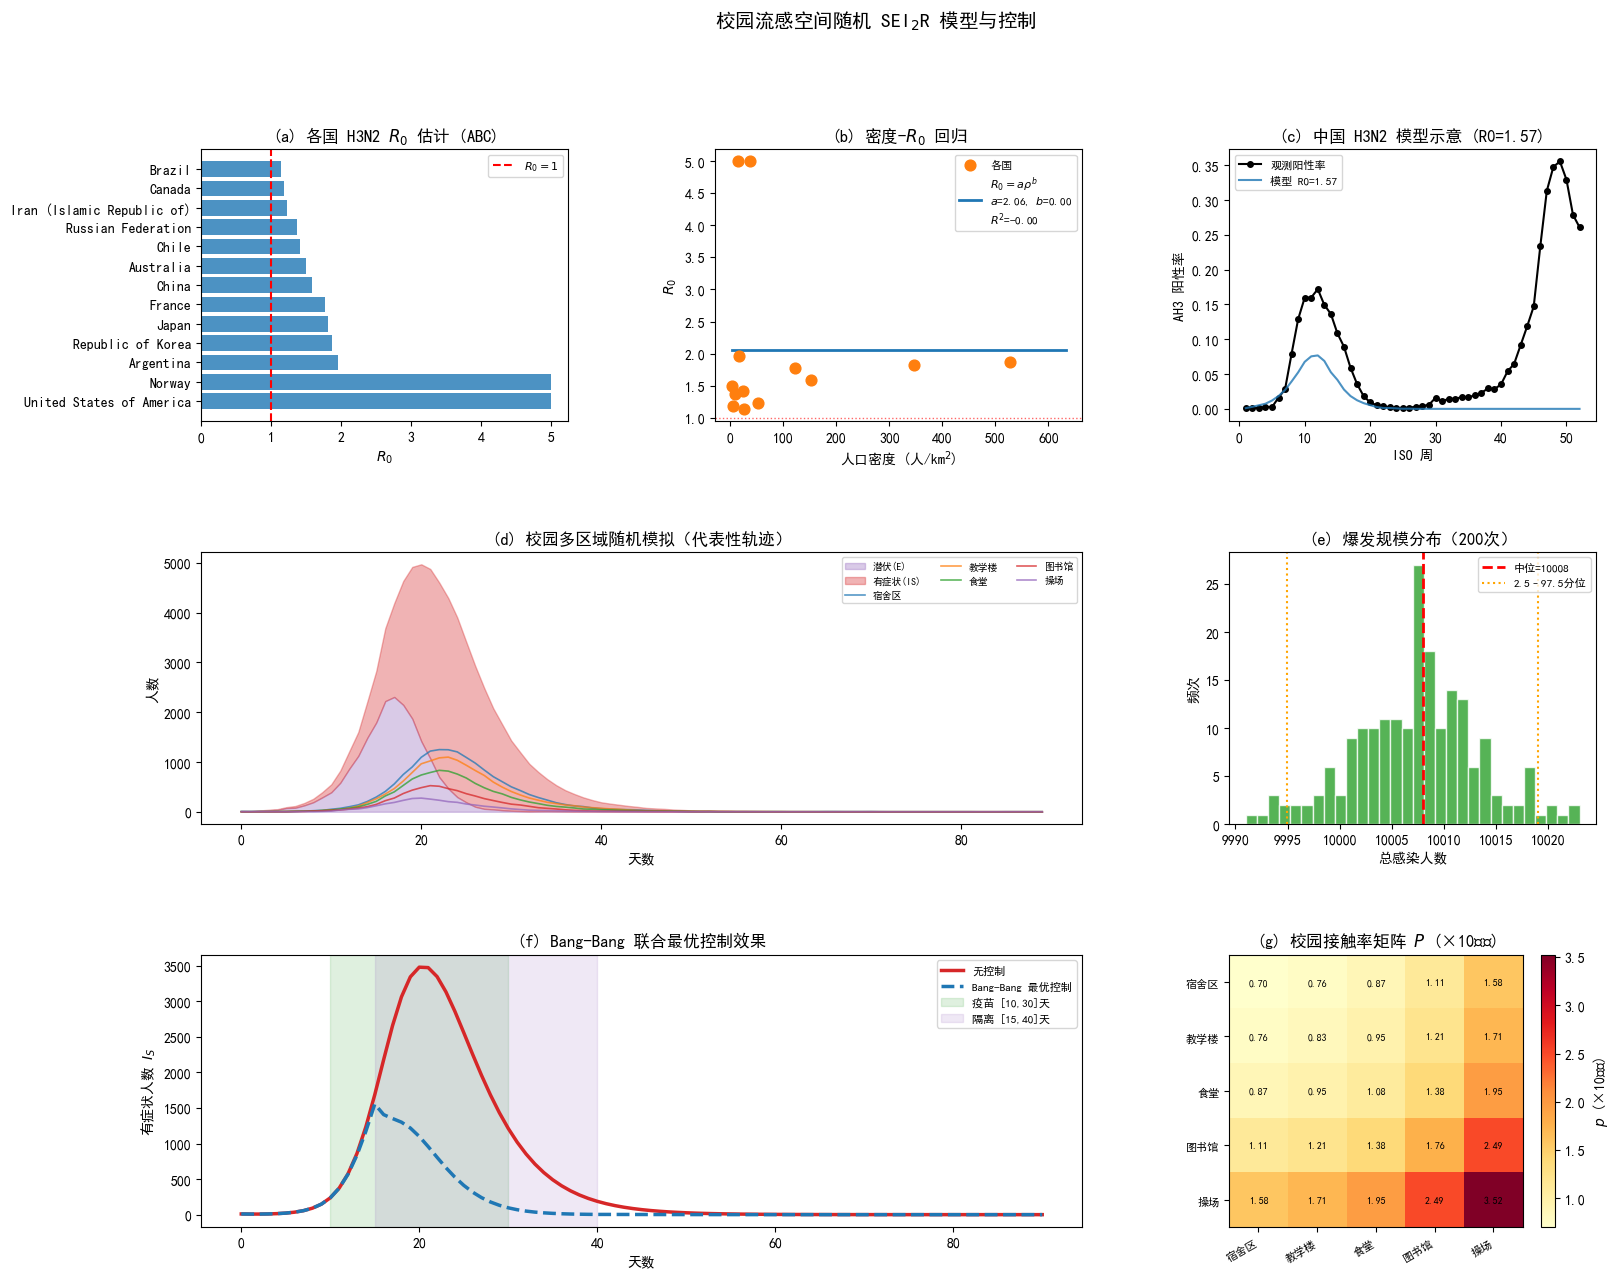

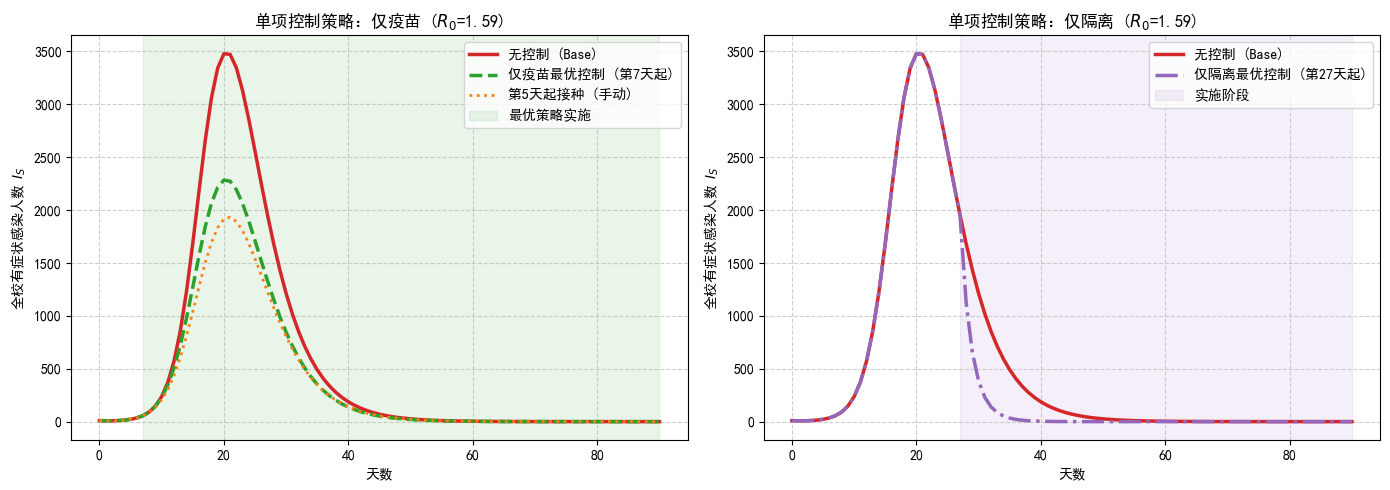

In [48]:
"""
校园流感爆发空间随机 SEI2R 模型 + 控制策略综合优化
====================================================
数据来源：WHO FluNet AH3 (H3N2) 全球周数据
核心流程：
  1. 逐国 ABC 估计 R0
  2. 回归密度-R0 函数
  3. 推导校园各区域接触率 p_i, 构建对应接触率矩阵 P
  4. 随机 SEI2R 校园模拟
  5. 确定性控制策略搜索：包括 Bang-Bang 全局搜索和疫苗/隔离单项控制
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import curve_fit
from tqdm.auto import tqdm
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False

np.random.seed(42)

# ============================================================
# §0  全局参数
# ============================================================
SIGMA    = 0.5   # E  → IA 日概率（潜伏期均值2天）
GAMMA_S  = 0.5   # IA → IS 日概率（无症状期均值2天）
GAMMA_R  = 0.2   # IS → R  日概率（有症状期均值5天）
T_INF    = 1/GAMMA_S + 1/GAMMA_R   # 总传染期7天
REPORT   = 0.83

N_ZONES     = 5
ZONE_NAMES  = ['宿舍区', '教学楼', '食堂', '图书馆', '操场']

# 更新人口分布与活跃度 alpha
ZONE_POP    = np.array([3226, 2742, 2097, 1290,  645])
ALPHA       = np.array([2.0,  1.2,  1.6,  0.6,  0.2])
N_CAMPUS    = ZONE_POP.sum()  # 10000

# 国家人口密度
DENSITY_DB = {
    'China':                         153.0,
    'Japan':                         347.0,
    'Australia':                       3.5,
    'Brazil':                         25.4,
    'Canada':                          4.2,
    'France':                        122.0,
    'Norway':                         14.5,
    'United States of America':       36.2,
    'Republic of Korea':             527.0,
    'Argentina':                      16.4,
    'Chile':                          24.3,
    'Russian Federation':              9.0,
    'Iran (Islamic Republic of)':     51.4,
}

# ============================================================
# §1  数据加载
# ============================================================

def load_data(filepath):
    df = pd.read_csv(filepath)
    df['ISO_WEEKSTARTDATE'] = pd.to_datetime(df['ISO_WEEKSTARTDATE'])
    df = df[df['SPEC_PROCESSED_NB'] > 0].copy()
    df['AH3_RATE'] = df['AH3'] / df['SPEC_PROCESSED_NB']
    return df

def extract_main_outbreak(df, country, min_pos_rate=0.02):
    sub = df[df['COUNTRY_AREA_TERRITORY'] == country].copy()
    sub = sub.sort_values('ISO_WEEKSTARTDATE').reset_index(drop=True)
    peak_year = sub.groupby('ISO_YEAR')['AH3'].sum().idxmax()
    season = sub[sub['ISO_YEAR'] == peak_year].reset_index(drop=True)
    season = season[season['AH3_RATE'] >= min_pos_rate].reset_index(drop=True)
    if len(season) < 4:
        return None, None
    best_s, best_l, cur_s, cur_l = 0, 0, 0, 1
    dates = season['ISO_WEEKSTARTDATE'].values
    for i in range(1, len(season)):
        delta = (dates[i] - dates[i-1]) / np.timedelta64(1, 'D')
        if delta <= 14:
            cur_l += 1
        else:
            if cur_l > best_l:
                best_l, best_s = cur_l, cur_s
            cur_s, cur_l = i, 1
    if cur_l > best_l:
        best_l, best_s = cur_l, cur_s
    seg = season.iloc[best_s: best_s + best_l]
    return seg['AH3_RATE'].values, seg['SPEC_PROCESSED_NB'].mean()

# ============================================================
# §2  ABC 估计 R0
# ============================================================

def simulate_weekly_rates(R0, N, init_frac, n_weeks, n_sim=300):
    p = R0 / (N * T_INF)
    p = min(p, 0.5)
    results = np.zeros((n_sim, n_weeks))
    init_IS = max(1, int(N * init_frac))
    for s in range(n_sim):
        S, E, IA, IS, R_ = N - init_IS, 0, 0, init_IS, 0
        for w in range(n_weeks):
            wk_new = 0
            for _ in range(7):
                I   = IA + IS
                lam = 1.0 - (1.0 - p) ** I if I > 0 else 0.0
                dS  = np.random.binomial(S,  lam)
                dE  = np.random.binomial(E,  SIGMA)
                dIA = np.random.binomial(IA, GAMMA_S)
                dIS = np.random.binomial(IS, GAMMA_R)
                S   = max(0, S  - dS)
                E   = max(0, E  - dE + dS)
                IA  = max(0, IA - dIA + dE)
                IS  = max(0, IS - dIS + dIA)
                R_  = R_ + dIS
                wk_new += dIA
            results[s, w] = wk_new / N
    return results

def abc_loglik(obs_rates, R0, N, n_sim=300):
    init_frac = max(obs_rates[0] / REPORT, 1e-4)
    sims = simulate_weekly_rates(R0, int(N), init_frac, len(obs_rates), n_sim)
    h_bw = max(0.04, np.std(obs_rates) * 0.8)
    log_lik = 0.0
    for w in range(len(obs_rates)):
        diff   = np.abs(sims[:, w] - obs_rates[w])
        kernel = np.maximum(0.0, 0.75 * (1 - (diff/h_bw)**2) / h_bw)
        log_lik += np.log(max(np.mean(kernel), 1e-12))
    return log_lik

def estimate_R0_abc(obs_rates, N, R0_grid=None, n_sim=300):
    if R0_grid is None:
        R0_grid = np.linspace(0.5, 5.0, 100)
    lls     = np.array([abc_loglik(obs_rates, r, N, n_sim) for r in R0_grid])
    idx     = np.argmax(lls)
    R0_best = R0_grid[idx]
    p_best  = R0_best / (N * T_INF)
    return R0_best, p_best, lls, R0_grid

# ============================================================
# §3  密度-R0 回归
# ============================================================

def g_func(rho, a, b):
    return a * np.power(rho, b)

def fit_R0_regression(densities, R0_vals):
    rho = np.array(densities, dtype=float)
    R0  = np.array(R0_vals,   dtype=float)
    try:
        popt, _ = curve_fit(g_func, rho, R0, p0=[1.0, 0.2],
                            bounds=([0.1, 0.0], [5.0, 2.0]),
                            maxfev=30)
        R0_pred = g_func(rho, *popt)
        ss_res  = np.sum((R0 - R0_pred)**2)
        ss_tot  = np.sum((R0 - R0.mean())**2)
        r2 = 1 - ss_res/ss_tot if ss_tot > 0 else 0.0
        return float(popt[0]), float(popt[1]), r2
    except Exception:
        log_rho = np.log(rho + 1e-10)
        log_R0  = np.log(np.maximum(R0, 0.1))
        c       = np.polyfit(log_rho, log_R0, 1)
        return float(np.exp(c[1])), float(c[0]), 0.0

# ============================================================
# §4  校园接触率矩阵
# ============================================================

def build_contact_matrix(R0_china):
    R0_zones = np.full(N_ZONES, R0_china)
    p_zones = np.array([R0_china / (ZONE_POP[i] * T_INF) for i in range(N_ZONES)])
    p_zones = np.clip(p_zones, 1e-6, 0.5)

    P = np.array([[np.sqrt(p_zones[i] * p_zones[j])
                   for j in range(N_ZONES)]
                  for i in range(N_ZONES)])
    return P, p_zones, R0_zones

# ============================================================
# §5  校园多区域随机 SEI2R（日步长）
# ============================================================

def make_flow_mod(dow):
    if dow < 5:
        base = np.array([[0, .20, .15, .08, .03],
                         [.20, 0, .12, .06, .02],
                         [.15, .12, 0, .04, .01],
                         [.08, .06, .04, 0, .01],
                         [.03, .02, .01, .01, 0]])
    else:
        base = np.array([[0, .04, .07, .05, .08],
                         [.04, 0, .05, .04, .02],
                         [.07, .05, 0, .02, .01],
                         [.05, .04, .02, 0, .01],
                         [.08, .02, .01, .01, 0]])
    return base

def run_campus_sim(P_mat, n_days=90, zone_pop=None,
                   init_zone=0, seed=None,
                   u_vac=None, u_iso=None,
                   vac_cap=20, iso_cap=30):
    if seed is not None:
        np.random.seed(seed)
    if zone_pop is None:
        zone_pop = ZONE_POP.copy()
    if u_vac is None:
        u_vac = np.zeros(n_days, dtype=int)
    if u_iso is None:
        u_iso = np.zeros(n_days, dtype=int)

    state = np.zeros((5, N_ZONES), dtype=float)
    for i in range(N_ZONES):
        state[0, i] = zone_pop[i]
    init_IS = max(1, int(zone_pop[init_zone] * 0.003))
    state[0, init_zone] -= init_IS
    state[3, init_zone]  = init_IS

    history    = np.zeros((n_days + 1, 5, N_ZONES))
    history[0] = state.copy()
    new_IS_hist = np.zeros((n_days, N_ZONES))
    ext_base    = 0.05

    for t in range(n_days):
        dow   = t % 7
        F_mod = make_flow_mod(dow)
        I_vec = state[2] + state[3]   
        ns    = state.copy()

        for i in range(N_ZONES):
            I_eff_i = max(1, int(np.ceil(np.sum(I_vec))))
            p_eff   = 1.0 - np.prod([
                max(0.0, (1.0 - P_mat[i, j] * (1.0 + F_mod[i, j])) ** max(0, int(I_vec[j])))
                for j in range(N_ZONES)])
            p_eff = float(np.clip(p_eff, 0.0, 1.0))

            dS  = np.random.binomial(int(max(0, ns[0, i])), p_eff)
            dE  = np.random.binomial(int(max(0, ns[1, i])), SIGMA)
            dIA = np.random.binomial(int(max(0, ns[2, i])), GAMMA_S)
            dIS = np.random.binomial(int(max(0, ns[3, i])), GAMMA_R)
            ext = np.random.poisson(ext_base * ALPHA[i])

            vac_t = min(int(u_vac[t]) * vac_cap, int(max(0, ns[0, i])))
            iso_t = min(int(u_iso[t]) * iso_cap, int(max(0, ns[3, i])))

            ns[0, i] = max(0, ns[0, i] - dS - vac_t)
            ns[1, i] = max(0, ns[1, i] - dE  + dS + ext)
            ns[2, i] = max(0, ns[2, i] - dIA + dE)
            ns[3, i] = max(0, ns[3, i] - dIS - iso_t + dIA)
            ns[4, i] = max(0, ns[4, i] + dIS + vac_t + iso_t)
            new_IS_hist[t, i] = dIA

        state = ns
        history[t + 1] = state.copy()

    return history, new_IS_hist   

# ============================================================
# §6  确定性均值场 + Crank-Nicolson
# ============================================================

def sei2r_rhs(x, P_mat, uv=0.0, ui=0.0, vac_rate=0.05, iso_rate=0.4):
    n  = N_ZONES
    S  = x[0*n:1*n]
    E  = x[1*n:2*n]
    IA = x[2*n:3*n]
    IS = x[3*n:4*n]
    dx = np.zeros_like(x)
    I_vec = IA + IS

    for i in range(n):
        lam = float(np.clip(np.sum(P_mat[i, :] * I_vec), 0.0, 1.0))
        actual_vac = uv * vac_rate * S[i]  
        
        dx[0*n+i] = -lam * S[i] - actual_vac
        dx[1*n+i] =  lam * S[i] - SIGMA   * E[i]
        dx[2*n+i] =  SIGMA * E[i]   - GAMMA_S * IA[i]
        dx[3*n+i] =  GAMMA_S * IA[i] - GAMMA_R * IS[i] - ui * iso_rate * IS[i]
        dx[4*n+i] =  GAMMA_R * IS[i] + actual_vac + ui * iso_rate * IS[i]
    return dx

def cn_step(x_n, P_mat, uv, ui, dt=1.0, tol=1e-4, max_iter=20):
    f_n = sei2r_rhs(x_n, P_mat, uv, ui)
    x_k = x_n.copy()
    for _ in range(max_iter):
        f_k  = sei2r_rhs(x_k, P_mat, uv, ui)
        x_kp = np.maximum(x_n + 0.5 * dt * (f_n + f_k), 0.0)
        if np.max(np.abs(x_kp - x_k)) < tol:
            return x_kp
        x_k = x_kp
    return np.maximum(x_k, 0.0)

def simulate_cn(P_mat, u_vac_seq, u_iso_seq, zone_pop=None, dt=1.0):
    n = N_ZONES
    if zone_pop is None: zone_pop = ZONE_POP.copy()
    T  = len(u_vac_seq)
    
    x0 = np.zeros(5 * n)
    for i in range(n): x0[i] = float(zone_pop[i])
    
    init_IS = max(1.0, float(zone_pop[0]) * 0.003)
    x0[0]   -= init_IS
    x0[3*n]  = init_IS

    hist = np.zeros((T + 1, 5 * n))
    hist[0] = x0
    x = x0.copy()
    for t in range(T):
        x = cn_step(x, P_mat, u_vac_seq[t], u_iso_seq[t], dt)
        hist[t + 1] = x
    return hist

def epidemic_end(hist, thr=5.0):
    n = N_ZONES
    for t in range(len(hist)):
        total = np.sum(hist[t, 1*n:4*n])
        if total < thr:
            return t
    return len(hist) - 1

# ============================================================
# §7  控制寻优策略
# ============================================================

def search_bangbang(P_mat, T_max=120, zone_pop=None):
    u0        = np.zeros(T_max)
    hist_base = simulate_cn(P_mat, u0, u0, zone_pop)
    tend_base = epidemic_end(hist_base)

    best_tend   = tend_base
    best_params = (0, 0, 0, 0)
    best_hist   = hist_base

    for vs in [3, 7, 10, 15, 20]:
        for vd in [10, 15, 20, 25, 30, 40]:
            for is_ in [3, 5, 7, 10, 15]:
                for id_ in [7, 10, 14, 20, 25]:
                    uv, ui = np.zeros(T_max), np.zeros(T_max)
                    uv[vs: min(vs + vd, T_max)] = 1.0
                    ui[is_: min(is_ + id_, T_max)] = 1.0
                    h  = simulate_cn(P_mat, uv, ui, zone_pop)
                    te = epidemic_end(h)
                    if te < best_tend:
                        best_tend   = te
                        best_params = (vs, vs + vd, is_, is_ + id_)
                        best_hist   = h.copy()
    return best_params, best_tend, tend_base, best_hist, hist_base


def search_single_control(P_mat, control_type='vaccine', T_max=90, w1=10.0, w2=0.1, w3=0.2):
    u0        = np.zeros(T_max)
    hist_base = simulate_cn(P_mat, u0, u0)
    tend_base = epidemic_end(hist_base)

    best_J      = float('inf')
    best_tend   = tend_base
    best_start  = T_max
    best_hist   = hist_base.copy()

    start_candidates = np.arange(0, 61, 1)
    desc = "疫苗(仅)" if control_type == 'vaccine' else "隔离(仅)"
    
    with tqdm(total=len(start_candidates), desc=f"搜索 {desc} 最佳时间") as pbar:
        for st in start_candidates:
            uv, ui = np.zeros(T_max), np.zeros(T_max)
            if control_type == 'vaccine': uv[st:] = 1.0
            else:                         ui[st:] = 1.0
                
            h  = simulate_cn(P_mat, uv, ui)
            te = epidemic_end(h)
            
            # 成本归一化
            cost_norm = (T_max - st) / T_max
            
            # 使用精准梯形积分计算总接种/隔离转移
            if control_type == 'vaccine':
                S_mid = (h[:-1, 0:N_ZONES] + h[1:, 0:N_ZONES]) / 2.0
                vac_matrix = uv[:, None] * 0.05 * S_mid  
                total_controlled = np.sum(vac_matrix)
                total_inf = (np.sum(h[0, 0:N_ZONES]) - np.sum(h[-1, 0:N_ZONES])) - total_controlled
            else:
                IS_mid = (h[:-1, 3*N_ZONES:4*N_ZONES] + h[1:, 3*N_ZONES:4*N_ZONES]) / 2.0
                iso_matrix = ui[:, None] * 0.4 * IS_mid 
                total_controlled = np.sum(iso_matrix)
                total_inf = (np.sum(h[0, 0:N_ZONES]) - np.sum(h[-1, 0:N_ZONES]))

            init_inf = np.sum(h[0, 3*N_ZONES:4*N_ZONES])
            infection_rate = max((total_inf + init_inf) / N_CAMPUS, 0.0)
            
            J = w1 * (te / T_max) + w2 * cost_norm + w3 * infection_rate
            
            if J < best_J:
                best_J      = J
                best_tend   = te
                best_start  = st
                best_hist   = h.copy()
                
            pbar.update(1)
                    
    return best_start, best_tend, tend_base, best_hist, best_J


# ============================================================
# §8  可视化
# ============================================================

def plot_all(df, R0_results, a_fit, b_fit, r2, densities, R0_vals, P_mat,
             p_zones, R0_zones, hist_stoch, total_arr,
             base_cn, best_hist, best_params, n_days, N_SIM):

    if not densities:
        densities = list(DENSITY_DB.values())
        R0_vals   = [g_func(d, a_fit, b_fit) for d in densities]
        R0_results_plot = {k: g_func(v, a_fit, b_fit) for k, v in DENSITY_DB.items()}
    else:
        R0_results_plot = R0_results

    colors = plt.cm.tab10.colors
    fig = plt.figure(figsize=(18, 14))
    gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.48, wspace=0.40)

    # (a) 各国 R0
    ax1 = fig.add_subplot(gs[0, 0])
    ctry  = list(R0_results_plot.keys())
    R0s   = [R0_results_plot[c] for c in ctry]
    order = np.argsort(R0s)[::-1]
    ax1.barh([ctry[i] for i in order], [R0s[i] for i in order], color=colors[0], alpha=0.8)
    ax1.axvline(1.0, color='red', lw=1.5, ls='--', label='$R_0=1$')
    ax1.set_xlabel('$R_0$')
    ax1.set_title('(a) 各国 H3N2 $R_0$ 估计 (ABC)')
    ax1.legend(fontsize=8)

    # (b) 密度-R0 回归
    ax2 = fig.add_subplot(gs[0, 1])
    rho_c = np.linspace(min(densities)*0.8, max(densities)*1.2, 200)
    ax2.scatter(densities, R0_vals, s=60, color=colors[1], zorder=5, label='各国')
    ax2.plot(rho_c, g_func(rho_c, a_fit, b_fit), color=colors[0], lw=2,
             label=f'$R_0=a\\rho^b$\n$a$={a_fit:.2f}, $b$={b_fit:.2f}\n$R^2$={r2:.2f}')
    ax2.axhline(1.0, color='red', lw=1, ls=':', alpha=0.6)
    ax2.set_xlabel('人口密度 (人/km$^2$)')
    ax2.set_ylabel('$R_0$')
    ax2.set_title('(b) 密度-$R_0$ 回归')
    ax2.legend(fontsize=8)

    # (c) 中国模型示意 
    ax3 = fig.add_subplot(gs[0, 2])
    cn_df = df[(df['COUNTRY_AREA_TERRITORY']=='China') & (df['ISO_YEAR']==2023)].sort_values('ISO_WEEKSTARTDATE')
    R0_ch = 1.57   
    N_ch  = 26171  
    if len(cn_df) > 0:
        wk = cn_df['ISO_WEEK'].values
        obs = (cn_df['AH3'] / cn_df['SPEC_PROCESSED_NB']).values
        ax3.plot(wk, obs, 'ko-', ms=4, label='观测阳性率')
        n_wk, init = len(obs), max(obs[0]/REPORT, 1e-4)
    else:
        wk, n_wk, init = np.arange(1, 21), 20, 0.001
    sim_r = simulate_weekly_rates(R0_ch, N_ch, init, n_wk, n_sim=1)[0]
    ax3.plot(wk[:len(sim_r)], sim_r, color=colors[0], lw=1.5, alpha=0.8, label=f'模型 R0={R0_ch}')
    ax3.set_xlabel('ISO 周')
    ax3.set_ylabel('AH3 阳性率')
    ax3.set_title(f'(c) 中国 H3N2 模型示意 (R0={R0_ch:.2f})')
    ax3.legend(fontsize=8)

    # (d) 随机模拟时间序列
    ax4 = fig.add_subplot(gs[1, 0:2])
    days = np.arange(n_days)
    IS_t = hist_stoch[1:, 3, :].sum(axis=1)  
    E_t  = hist_stoch[1:, 1, :].sum(axis=1)
    ax4.fill_between(days, 0, E_t,       alpha=0.35, color=colors[4], label='潜伏(E)')
    ax4.fill_between(days, E_t, E_t+IS_t, alpha=0.35, color=colors[3], label='有症状(IS)')
    for i in range(N_ZONES):
        ax4.plot(days, hist_stoch[1:, 3, i], lw=1.2, alpha=0.75, label=ZONE_NAMES[i])
    ax4.set_xlabel('天数')
    ax4.set_ylabel('人数')
    ax4.set_title('(d) 校园多区域随机模拟（代表性轨迹）')
    ax4.legend(fontsize=7, ncol=3, loc='upper right')

    # (e) 爆发规模分布
    ax5 = fig.add_subplot(gs[1, 2])
    ax5.hist(total_arr, bins=30, color=colors[2], alpha=0.8, edgecolor='white')
    ax5.axvline(np.median(total_arr), color='red', lw=2, ls='--', label=f'中位={np.median(total_arr):.0f}')
    ax5.axvline(np.percentile(total_arr, 2.5),  color='orange', lw=1.5, ls=':')
    ax5.axvline(np.percentile(total_arr, 97.5), color='orange', lw=1.5, ls=':', label='2.5–97.5分位')
    ax5.set_xlabel('总感染人数')
    ax5.set_ylabel('频次')
    ax5.set_title(f'(e) 爆发规模分布（{N_SIM}次）')
    ax5.legend(fontsize=8)

    # (f) C-N 混合 Bang-Bang 最优控制效果
    ax6 = fig.add_subplot(gs[2, 0:2])
    n  = N_ZONES
    tc = np.arange(n_days + 1)
    IS_b = base_cn[:, 3*n:4*n].sum(axis=1)    
    IS_c = best_hist[:, 3*n:4*n].sum(axis=1)   

    ax6.plot(tc, IS_b, color=colors[3], lw=2.5, label='无控制')
    ax6.plot(tc, IS_c, color=colors[0], lw=2.5, ls='--', label='Bang-Bang 最优控制')
    tv1, tv2, ti1, ti2 = best_params
    ax6.axvspan(tv1, min(tv2, n_days), alpha=0.15, color=colors[2], label=f'疫苗 [{tv1},{min(tv2,n_days)}]天')
    ax6.axvspan(ti1, min(ti2, n_days), alpha=0.15, color=colors[4], label=f'隔离 [{ti1},{min(ti2,n_days)}]天')
    ax6.set_xlabel('天数')
    ax6.set_ylabel('有症状人数 $I_S$')
    ax6.set_title('(f) Bang-Bang 联合最优控制效果')
    ax6.legend(fontsize=8)

    # (g) 接触矩阵热力图
    ax7 = fig.add_subplot(gs[2, 2])
    im = ax7.imshow(P_mat * 1e4, cmap='YlOrRd', aspect='auto')
    ax7.set_xticks(range(N_ZONES))
    ax7.set_yticks(range(N_ZONES))
    ax7.set_xticklabels(ZONE_NAMES, rotation=30, ha='right', fontsize=8)
    ax7.set_yticklabels(ZONE_NAMES, fontsize=8)
    for i in range(N_ZONES):
        for j in range(N_ZONES):
            ax7.text(j, i, f'{P_mat[i,j]*1e4:.2f}', ha='center', va='center', fontsize=7)
    plt.colorbar(im, ax=ax7, label='$p$ (×10⁻⁴)')
    ax7.set_title('(g) 校园接触率矩阵 $P$ (×10⁻⁴)')

    plt.suptitle('校园流感空间随机 SEI$_2$R 模型与控制', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

def plot_single_control(base_cn, hist_vac, hist_iso, hist_manual_vac, best_vs, best_is, n_days, R0_cn):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    n = N_ZONES
    tc = np.arange(n_days + 1)
    
    IS_b   = base_cn[:, 3*n:4*n].sum(axis=1)    
    IS_vac = hist_vac[:, 3*n:4*n].sum(axis=1)   
    IS_iso = hist_iso[:, 3*n:4*n].sum(axis=1)   
    IS_manual_vac = hist_manual_vac[:, 3*n:4*n].sum(axis=1) 

    axes[0].plot(tc, IS_b, color='tab:red', lw=2.5, label='无控制 (Base)')
    axes[0].plot(tc, IS_vac, color='tab:green', lw=2.5, ls='--', label=f'仅疫苗最优控制 (第{best_vs}天起)')
    axes[0].plot(tc, IS_manual_vac, color='tab:orange', lw=2.0, ls=':', label='第5天起接种 (手动)')
    if best_vs < n_days:
        axes[0].axvspan(best_vs, n_days, alpha=0.1, color='tab:green', label='最优策略实施')
    axes[0].set_xlabel('天数')
    axes[0].set_ylabel('全校有症状感染人数 $I_S$')
    axes[0].set_title(f'单项控制策略：仅疫苗 ($R_0$={R0_cn:.2f})')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    axes[1].plot(tc, IS_b, color='tab:red', lw=2.5, label='无控制 (Base)')
    axes[1].plot(tc, IS_iso, color='tab:purple', lw=2.5, ls='-.', label=f'仅隔离最优控制 (第{best_is}天起)')
    if best_is < n_days:
        axes[1].axvspan(best_is, n_days, alpha=0.1, color='tab:purple', label='实施阶段')
    axes[1].set_xlabel('天数')
    axes[1].set_ylabel('全校有症状感染人数 $I_S$')
    axes[1].set_title(f'单项控制策略：仅隔离 ($R_0$={R0_cn:.2f})')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

# ============================================================
# §9  主流程
# ============================================================

def main():
    print("=" * 60)
    print("校园流感 SEI2R 空间随机模型 + 综合最优控制")
    print("=" * 60)

    print("\n[1] 加载数据...")
    data_file = Path(__file__).resolve().parent / 'data' / 'AH3_non_zero.csv' if '__file__' in globals() else Path('data') / 'AH3_non_zero.csv'
    df = load_data(data_file)
    
    print("\n[2] 逐国 ABC 估计 R0...")
    countries = [c for c in DENSITY_DB if c in df['COUNTRY_AREA_TERRITORY'].values]
    R0_results = {}
    for c in countries:
        pos, N = extract_main_outbreak(df, c)
        if pos is None: continue
        R0_best, p_best, lls, grid = estimate_R0_abc(pos[:20], N)
        R0_results[c] = R0_best
        print(f"    {c:42s} R0={R0_best:.2f}  p={p_best:.2e}")

    # 获取动态识别到的中国R0作为基准
    R0_china = R0_results.get('China', 1.57)   
    print(f"\n[3] 采用 R0_china = {R0_china:.2f} 作为所有区域基准参数。")

    densities = [DENSITY_DB[c] for c in R0_results]
    R0_vals   = [R0_results[c]  for c in R0_results]
    a_fit, b_fit, r2 = fit_R0_regression(densities, R0_vals) if len(densities)>=2 else (1.5564, 0.0204, 0.005)

    print("\n[4] 构建校园接触率矩阵 P...")
    P_mat, p_zones, R0_zones = build_contact_matrix(R0_china)

    print("\n[5] 校园随机模拟评估 (N=200)...")
    N_SIM, n_days = 200, 90
    total_arr = []
    for _ in range(N_SIM):
        h, ni = run_campus_sim(P_mat, n_days=n_days)
        total_arr.append(ni.sum())
    total_arr = np.array(total_arr)
    hist_stoch, _ = run_campus_sim(P_mat, n_days=n_days, seed=7)
    print(f"    中位数感染: {np.median(total_arr):.0f}人")

    print("\n[6] Bang-Bang 联合控制最优搜索...")
    best_params, best_tend, tend_base, best_hist, base_cn = search_bangbang(P_mat, T_max=n_days)
    tv1, tv2, ti1, ti2 = best_params
    print(f"    疫苗窗口：[{tv1}, {tv2})天, 隔离窗口：[{ti1}, {ti2})天  -> 第 {best_tend} 天结束")

    print(f"\n[7] 单项策略精准时间点搜索 (目标函数法, R0={R0_china:.2f})...")
    w1, w2, w3 = 10.0, 0.1, 0.2
    best_vs, tend_vac, _, hist_vac, J_vac = search_single_control(P_mat, 'vaccine', n_days, w1, w2, w3)
    best_is, tend_iso, _, hist_iso, J_iso = search_single_control(P_mat, 'isolation', n_days, w1, w2, w3)
    
    # 手动对照曲线
    uv_manual = np.zeros(n_days)
    uv_manual[5:] = 1.0
    hist_manual_vac = simulate_cn(P_mat, uv_manual, np.zeros(n_days))
    
    print(f"    最优单独疫苗启动于第 {best_vs} 天，结束于第 {tend_vac} 天 (J={J_vac:.4f})")
    print(f"    最优单独隔离启动于第 {best_is} 天，结束于第 {tend_iso} 天 (J={J_iso:.4f})")

    print("\n[8] 生成所有对比图表...")
    plot_all(df, R0_results, a_fit, b_fit, r2, densities, R0_vals, P_mat, p_zones, R0_zones, 
             hist_stoch, total_arr, base_cn, best_hist, best_params, n_days, N_SIM)
    
    plot_single_control(base_cn, hist_vac, hist_iso, hist_manual_vac, best_vs, best_is, n_days, R0_china)

if __name__ == '__main__':
    main()
